In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# View all dataset names - from seaborn
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [3]:
# Load the 'mpg' dataset
df = sns.load_dataset('mpg')

In [4]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [6]:
df=pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/Cars93_miss.csv')

In [7]:
df.head()

,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,Acura,Integra,Small,12.9,15.9,18.8,25.0,31.0,NaN,Front,...,5.0,177.0,102.0,68.0,37.0,26.5,NaN,2705.0,non-USA,Acura Integra
1,NaN,Legend,Midsize,29.2,33.9,38.7,18.0,25.0,Driver & Passenger,Front,...,5.0,195.0,115.0,71.0,38.0,30.0,15.0,3560.0,non-USA,Acura Legend
2,Audi,90,Compact,25.9,29.1,32.3,20.0,26.0,Driver only,Front,...,5.0,180.0,102.0,67.0,37.0,28.0,14.0,3375.0,non-USA,Audi 90
3,Audi,100,Midsize,NaN,37.7,44.6,19.0,26.0,Driver & Passenger,NaN,...,6.0,193.0,106.0,NaN,37.0,31.0,17.0,3405.0,non-USA,Audi 100
4,BMW,535i,Midsize,NaN,30.0,NaN,22.0,30.0,NaN,Rear,...,4.0,186.0,109.0,69.0,39.0,27.0,13.0,3640.0,non-USA,BMW 535i


In [8]:
df.isnull().sum()

Manufacturer           4
Model                  1
Type                   3
Min.Price              7
Price                  2
Max.Price              5
MPG.city               9
MPG.highway            2
AirBags               38
DriveTrain             7
Cylinders              5
EngineSize             2
Horsepower             7
RPM                    3
Rev.per.mile           6
Man.trans.avail        5
Fuel.tank.capacity     8
Passengers             2
Length                 4
Wheelbase              1
Width                  6
Turn.circle            5
Rear.seat.room         4
Luggage.room          19
Weight                 7
Origin                 5
Make                   3
dtype: int64

In [9]:
# percentage of missing values in each column
missing_percentage = ((df.isnull().sum()/len(df)).sort_values(ascending=False))*100

# NOTE
missing_percentage = ((df.isnull().sum()/len(df)).sort_values(ascending=False))*100

returns a Series because:

df.isnull() → DataFrame of booleans.

.sum() → sums each column, producing one value per column → a Series.

/ len(df) → still a Series.

.sort_values() on a Series → still a Series.

* 100 → still a Series.

In [10]:
missing_percentage = (
    (df.isnull().sum() / len(df) * 100)
    .sort_values(ascending=False)
    .to_frame(name='missing_percentage')
)

# If you want a DataFrame
type(missing_percentage)

pandas.DataFrame

In [11]:
# or to create a dataframe from the Series use
# without reset_index
# note pd. dataframe doesnt have index =false parameter
missing_percentage = pd.DataFrame({
    'column': df.columns,
    'missing_percentage': (df.isnull().sum() / len(df) * 100)
}).sort_values('missing_percentage', ascending=False)

print(missing_percentage)

                                column  missing_percentage
AirBags                        AirBags           40.860215
Luggage.room              Luggage.room           20.430108
MPG.city                      MPG.city            9.677419
Fuel.tank.capacity  Fuel.tank.capacity            8.602151
DriveTrain                  DriveTrain            7.526882
Horsepower                  Horsepower            7.526882
Min.Price                    Min.Price            7.526882
Weight                          Weight            7.526882
Rev.per.mile              Rev.per.mile            6.451613
Width                            Width            6.451613
Cylinders                    Cylinders            5.376344
Turn.circle                Turn.circle            5.376344
Max.Price                    Max.Price            5.376344
Man.trans.avail        Man.trans.avail            5.376344
Origin                          Origin            5.376344
Rear.seat.room          Rear.seat.room            4.3010

In [12]:
missing_percentage.info()

<class 'pandas.DataFrame'>
Index: 27 entries, AirBags to Model
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   column              27 non-null     str    
 1   missing_percentage  27 non-null     float64
dtypes: float64(1), str(1)
memory usage: 648.0+ bytes


In [13]:
# or to create a dataframe from the Series use
missing_percentage = pd.DataFrame({
    'column': df.columns,
    'missing_percentage': (df.isnull().sum() / len(df) * 100)
}).sort_values('missing_percentage', ascending=False).reset_index(drop=True)

print(missing_percentage)

                column  missing_percentage
0              AirBags           40.860215
1         Luggage.room           20.430108
2             MPG.city            9.677419
3   Fuel.tank.capacity            8.602151
4           DriveTrain            7.526882
5           Horsepower            7.526882
6            Min.Price            7.526882
7               Weight            7.526882
8         Rev.per.mile            6.451613
9                Width            6.451613
10           Cylinders            5.376344
11         Turn.circle            5.376344
12           Max.Price            5.376344
13     Man.trans.avail            5.376344
14              Origin            5.376344
15      Rear.seat.room            4.301075
16              Length            4.301075
17        Manufacturer            4.301075
18                 RPM            3.225806
19                Type            3.225806
20                Make            3.225806
21          Passengers            2.150538
22         

In [14]:
missing_percentage.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   column              27 non-null     str    
 1   missing_percentage  27 non-null     float64
dtypes: float64(1), str(1)
memory usage: 564.0 bytes


# Handling missing values

In [15]:
# 1. Drop columns with too many missing value- based on a thresholed

threshold = 0.39 * 100  # 39% threshold
columns_with_high_null_values = missing_percentage[missing_percentage['missing_percentage'] > threshold]['column'].tolist()

In [16]:
columns_with_high_null_values

['AirBags']

In [17]:
threshold = 0.39 * 100  # 39% threshold

columns_with_high_null_values = (
    missing_percentage[
        missing_percentage['missing_percentage'] > threshold
    ]['column']
    .tolist()
)

In [18]:
columns_with_high_null_values

['AirBags']

Let's break it down step by step.

### Suppose `missing_percentage` is:

```python
missing_percentage
```

| index | column   | missing_percentage |
| ----- | -------- | ------------------ |
| 0     | Cabin    | 77.10              |
| 1     | Age      | 19.87              |
| 2     | Embarked | 0.22               |

and

```python
threshold = 50
```

---

## Step 1: Create a boolean mask

```python
missing_percentage['missing_percentage'] > threshold
```

becomes:

```python
missing_percentage['missing_percentage'] > 50
```

Result:

```python
0     True
1    False
2    False
Name: missing_percentage, dtype: bool
```

This is a **boolean Series** telling Pandas which rows satisfy the condition.

---

## Step 2: Filter rows

```python
missing_percentage[
    missing_percentage['missing_percentage'] > threshold
]
```

Pandas keeps only rows where the mask is `True`.

Result:

| index | column | missing_percentage |
| ----- | ------ | ------------------ |
| 0     | Cabin  | 77.10              |

---

## Step 3: Select the `column` column

```python
missing_percentage[
    missing_percentage['missing_percentage'] > threshold
]['column']
```

Result:

```python
0    Cabin
Name: column, dtype: object
```

This is now a **Series** containing only the values from the `column` column.

---

## Step 4: Convert Series to Python list

```python
.tolist()
```

Result:

```python
['Cabin']
```

---

## Full flow

```python
columns_with_high_null_values = (
    missing_percentage[
        missing_percentage['missing_percentage'] > threshold
    ]
    ['column']
    .tolist()
)
```

Visualization:

```text
missing_percentage
        ↓
missing_percentage['missing_percentage'] > 50
        ↓
[True, False, False]
        ↓
Filter rows
        ↓
      column  missing_percentage
0     Cabin         77.10
        ↓
Select 'column'
        ↓
0    Cabin
        ↓
tolist()
        ↓
['Cabin']
```

---

## Cleaner version with `.loc`

Many Pandas users prefer:

```python
columns_with_high_null_values = (
    missing_percentage.loc[
        missing_percentage['missing_percentage'] > threshold,
        'column'
    ].tolist()
)
```

Read it as:

> "From `missing_percentage`, select rows where `missing_percentage > threshold`, and return the `column` column."

This is often easier to read than chained brackets.


In [19]:
df_1 = df.drop(columns=columns_with_high_null_values)

In [20]:
df_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Manufacturer        89 non-null     str    
 1   Model               92 non-null     str    
 2   Type                90 non-null     str    
 3   Min.Price           86 non-null     float64
 4   Price               91 non-null     float64
 5   Max.Price           88 non-null     float64
 6   MPG.city            84 non-null     float64
 7   MPG.highway         91 non-null     float64
 8   DriveTrain          86 non-null     str    
 9   Cylinders           88 non-null     str    
 10  EngineSize          91 non-null     float64
 11  Horsepower          86 non-null     float64
 12  RPM                 90 non-null     float64
 13  Rev.per.mile        87 non-null     float64
 14  Man.trans.avail     88 non-null     str    
 15  Fuel.tank.capacity  85 non-null     float64
 16  Passengers          9

In [21]:
import numpy as np
# Filter by importance
# (Correlation with salePrice)

target_coorelation = df_1.select_dtypes(include=[np.number]).corr()['Max.Price'].abs()

In [22]:
target_coorelation.sort_values(ascending=False)

Max.Price             1.000000
Price                 0.980252
Min.Price             0.895937
Horsepower            0.724528
Weight                0.571150
MPG.city              0.537724
Fuel.tank.capacity    0.526891
Length                0.519279
EngineSize            0.513480
MPG.highway           0.503579
Wheelbase             0.435722
Width                 0.391288
Rev.per.mile          0.356009
Rear.seat.room        0.342768
Turn.circle           0.335043
Luggage.room          0.318431
Passengers            0.049113
RPM                   0.017815
Name: Max.Price, dtype: float64

# MIND MAP TO HANDLE MISSING VALUES

```text
                    HANDLING MISSING VALUES IN ML
                               │
        ┌──────────────────────┼──────────────────────┐
        │                      │                      │
   1. Deletion           2. Imputation         3. Time-Series
        │                      │                      │
   ┌────┴────┐          ┌──────┼──────┐       ┌──────┼──────┐
   │         │          │      │      │       │             │
Rows      Columns     Mean  Median  Mode   Forward Fill  Backward Fill
(Delete   (Remove      │      │      │          │             │
Records) Features)     │      │      │          │             │
                        └──────┴──────┘       Interpolation
                                                  │
                                      ┌───────────┼───────────┐
                                      │           │           │
                                   Linear    Polynomial    Spline

                               │
                               ▼

                     4. Advanced Imputation
                               │
                ┌──────────────┼──────────────┐
                │              │              │
             KNN           Regression       MICE
          Imputation       Imputation   (Multiple Imputation)

                               │
                               ▼

                   5. Model-Based Handling
                               │
          ┌────────────────────┼────────────────────┐
          │                    │                    │
      XGBoost             LightGBM             CatBoost
   (Native Missing)   (Native Missing)   (Native Missing)

                               │
                               ▼

                    6. Missing Indicator
                               │
                Create Binary Feature
                (0 = Present, 1 = Missing)

                               │
                               ▼

                    7. Missing Data Types
                               │
        ┌──────────────────────┼──────────────────────┐
        │                      │                      │
      MCAR                   MAR                   MNAR
(Missing Completely    (Missing At        (Missing Not
   At Random)            Random)           At Random)
```

### Quick Memory Trick

**D-I-T-A-M**

* **D** → Deletion
* **I** → Imputation (Mean, Median, Mode)
* **T** → Time-series methods (FFill, BFill, Interpolation)
* **A** → Advanced methods (KNN, Regression, MICE)
* **M** → Model-based handling + Missing Indicator


In [23]:
low_imapct_threshold = 0.1

# Interview Question : coorelation vs covariance
# Always use coorelation

low_impact_cols = target_coorelation[target_coorelation<low_imapct_threshold].index.to_list()
low_impact_cols

#Your code uses correlation to measure impact.

#If a column has very low correlation with the target, it means:

#“This feature does not strongly affect the output.”

['RPM', 'Passengers']

In [24]:
df_2 = df_1.drop(columns=low_impact_cols, errors='ignore')

In [25]:
# Removing multi-collinearity

corr_matrix = df_2.select_dtypes(include=[np.number]).corr().abs()

corr_matrix

,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,Rev.per.mile,Fuel.tank.capacity,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
Min.Price,1.000000,0.970502,0.895937,0.626182,0.586501,0.651442,0.807519,0.460744,0.609061,0.577413,0.522891,0.476436,0.465782,0.390591,0.423905,0.673889
Price,0.970502,1.000000,0.980252,0.596479,0.554859,0.607286,0.794607,0.422175,0.604777,0.564704,0.500840,0.432279,0.415628,0.366097,0.369545,0.642563
Max.Price,0.895937,0.980252,1.000000,0.537724,0.503579,0.513480,0.724528,0.356009,0.526891,0.519279,0.435722,0.391288,0.335043,0.342768,0.318431,0.571150
MPG.city,0.626182,0.596479,0.537724,1.000000,0.947916,0.718253,0.714274,0.709801,0.823445,0.676105,0.733983,0.715643,0.705238,0.431462,0.541337,0.883119
MPG.highway,0.586501,0.554859,0.503579,0.947916,1.000000,0.625965,0.643573,0.591147,0.785317,0.538247,0.644664,0.611958,0.599979,0.363202,0.360388,0.832360
EngineSize,0.651442,0.607286,0.513480,0.718253,0.625965,1.000000,0.731327,0.807026,0.778117,0.790721,0.742088,0.862513,0.784953,0.518073,0.702213,0.845244
Horsepower,0.807519,0.794607,0.724528,0.714274,0.643573,0.731327,1.000000,0.585919,0.741343,0.552906,0.483922,0.646497,0.596148,0.247775,0.382684,0.777764
Rev.per.mile,0.460744,0.422175,0.356009,0.709801,0.591147,0.807026,0.585919,1.000000,0.631850,0.676693,0.612762,0.754254,0.735520,0.327909,0.551099,0.723885
Fuel.tank.capacity,0.609061,0.604777,0.526891,0.823445,0.785317,0.778117,0.741343,0.631850,1.000000,0.700491,0.766788,0.810474,0.703818,0.537124,0.682485,0.905157
Length,0.577413,0.564704,0.519279,0.676105,0.538247,0.790721,0.552906,0.676693,0.700491,1.000000,0.827515,0.820668,0.749630,0.548242,0.716085,0.813305


In [26]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
upper

,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,Rev.per.mile,Fuel.tank.capacity,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
Min.Price,NaN,0.970502,0.895937,0.626182,0.586501,0.651442,0.807519,0.460744,0.609061,0.577413,0.522891,0.476436,0.465782,0.390591,0.423905,0.673889
Price,NaN,NaN,0.980252,0.596479,0.554859,0.607286,0.794607,0.422175,0.604777,0.564704,0.500840,0.432279,0.415628,0.366097,0.369545,0.642563
Max.Price,NaN,NaN,NaN,0.537724,0.503579,0.513480,0.724528,0.356009,0.526891,0.519279,0.435722,0.391288,0.335043,0.342768,0.318431,0.571150
MPG.city,NaN,NaN,NaN,NaN,0.947916,0.718253,0.714274,0.709801,0.823445,0.676105,0.733983,0.715643,0.705238,0.431462,0.541337,0.883119
MPG.highway,NaN,NaN,NaN,NaN,NaN,0.625965,0.643573,0.591147,0.785317,0.538247,0.644664,0.611958,0.599979,0.363202,0.360388,0.832360
EngineSize,NaN,NaN,NaN,NaN,NaN,NaN,0.731327,0.807026,0.778117,0.790721,0.742088,0.862513,0.784953,0.518073,0.702213,0.845244
Horsepower,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.585919,0.741343,0.552906,0.483922,0.646497,0.596148,0.247775,0.382684,0.777764
Rev.per.mile,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.631850,0.676693,0.612762,0.754254,0.735520,0.327909,0.551099,0.723885
Fuel.tank.capacity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700491,0.766788,0.810474,0.703818,0.537124,0.682485,0.905157
Length,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.827515,0.820668,0.749630,0.548242,0.716085,0.813305


In [27]:
redundant_cols = [column for column in upper.columns if any(upper[column] > 0.95)]
print(redundant_cols)

# removing redudant columns
df_3 = df_2.drop(columns=redundant_cols, errors='ignore')

['Price', 'Max.Price']


In [28]:
df_3.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Manufacturer        89 non-null     str    
 1   Model               92 non-null     str    
 2   Type                90 non-null     str    
 3   Min.Price           86 non-null     float64
 4   MPG.city            84 non-null     float64
 5   MPG.highway         91 non-null     float64
 6   DriveTrain          86 non-null     str    
 7   Cylinders           88 non-null     str    
 8   EngineSize          91 non-null     float64
 9   Horsepower          86 non-null     float64
 10  Rev.per.mile        87 non-null     float64
 11  Man.trans.avail     88 non-null     str    
 12  Fuel.tank.capacity  85 non-null     float64
 13  Length              89 non-null     float64
 14  Wheelbase           92 non-null     float64
 15  Width               87 non-null     float64
 16  Turn.circle         8

In [29]:
# mean imputation for missing values

# (a) Mean Imputation (Numerical Data)
# LotFrontage
# Pull distribution towards the mean --> underestimates variance.

df_mean=df_3.copy()
df_mean.fillna({"Min.Price": df_mean['Min.Price'].mean(),
                "Cylinders": df_mean['Cylinders'].mode()
                }, inplace=True)

# A dictionary is used in fillna() because it lets you specify different fill values for different columns in a single call

,Manufacturer,Model,Type,Min.Price,MPG.city,MPG.highway,DriveTrain,Cylinders,EngineSize,Horsepower,...,Fuel.tank.capacity,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,Acura,Integra,Small,12.900000,25.0,31.0,Front,4,1.8,140.0,...,13.2,177.0,102.0,68.0,37.0,26.5,NaN,2705.0,non-USA,Acura Integra
1,NaN,Legend,Midsize,29.200000,18.0,25.0,Front,6,3.2,200.0,...,18.0,195.0,115.0,71.0,38.0,30.0,15.0,3560.0,non-USA,Acura Legend
2,Audi,90,Compact,25.900000,20.0,26.0,Front,6,2.8,172.0,...,16.9,180.0,102.0,67.0,37.0,28.0,14.0,3375.0,non-USA,Audi 90
3,Audi,100,Midsize,17.118605,19.0,26.0,NaN,6,NaN,172.0,...,21.1,193.0,106.0,NaN,37.0,31.0,17.0,3405.0,non-USA,Audi 100
4,BMW,535i,Midsize,17.118605,22.0,30.0,Rear,4,3.5,208.0,...,21.1,186.0,109.0,69.0,39.0,27.0,13.0,3640.0,non-USA,BMW 535i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,Volkswagen,Eurovan,Van,16.600000,17.0,21.0,Front,5,2.5,109.0,...,21.1,187.0,115.0,72.0,38.0,34.0,NaN,3960.0,NaN,Volkswagen Eurovan
89,Volkswagen,Passat,Compact,17.600000,21.0,30.0,Front,4,2.0,134.0,...,18.5,180.0,103.0,67.0,35.0,31.5,14.0,2985.0,non-USA,Volkswagen Passat
90,Volkswagen,Corrado,Sporty,22.900000,18.0,25.0,Front,6,2.8,178.0,...,18.5,159.0,97.0,66.0,36.0,26.0,15.0,2810.0,non-USA,Volkswagen Corrado
91,Volvo,240,Compact,21.800000,21.0,28.0,Rear,NaN,2.3,114.0,...,15.8,190.0,104.0,67.0,37.0,29.5,14.0,2985.0,non-USA,Volvo 240


# IMPORTANT 

To impute missing values in Pandas, use .fillna() combined with .median() for numerical data and .mode() for categorical data. Never use the mean or median for nominal data; use the mode. For ordinal data, either the mode or the median of encoded categories is appropriate"

### Simple Imputation

Instead of deleting, we fill the missing values with estimates.

(a) Mean Imputation (Numerical Data)

(b) Median Imputation (Numerical Data)

(c) Mode Imputation (Categorical Data)

# Compare Before and After Imputation

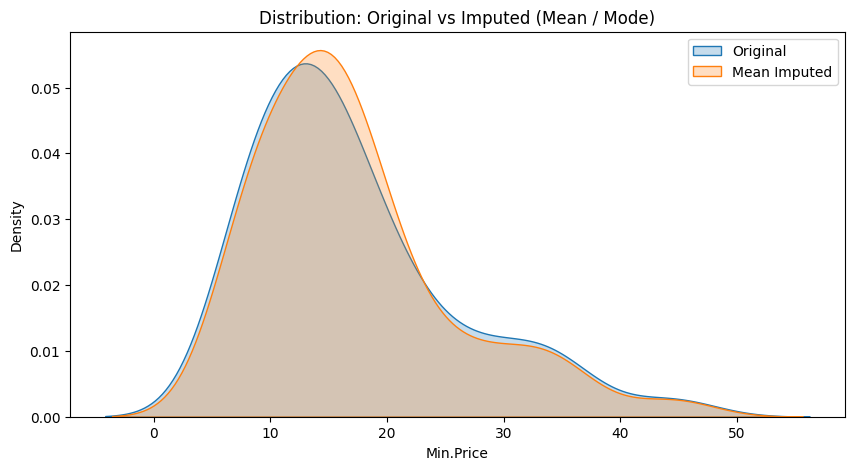

In [30]:
plt.figure(figsize=(10,5))
# kdeplot --> plot that shows pdf
sns.kdeplot(df["Min.Price"], label="Original", fill=True)
sns.kdeplot(df_mean["Min.Price"], label="Mean Imputed", fill=True)
# sns.kdeplot(df_mean["Cylinders"], label="Mode Imputed", fill=True) 
# - As the distribution chart is for numerical data, we will not plot the mode imputed column as it is categorical
plt.legend()
plt.title("Distribution: Original vs Imputed (Mean / Mode)")
plt.show()

In [31]:
df_mean.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Manufacturer        89 non-null     str    
 1   Model               92 non-null     str    
 2   Type                90 non-null     str    
 3   Min.Price           93 non-null     float64
 4   MPG.city            84 non-null     float64
 5   MPG.highway         91 non-null     float64
 6   DriveTrain          86 non-null     str    
 7   Cylinders           88 non-null     str    
 8   EngineSize          91 non-null     float64
 9   Horsepower          86 non-null     float64
 10  Rev.per.mile        87 non-null     float64
 11  Man.trans.avail     88 non-null     str    
 12  Fuel.tank.capacity  85 non-null     float64
 13  Length              89 non-null     float64
 14  Wheelbase           92 non-null     float64
 15  Width               87 non-null     float64
 16  Turn.circle         8

# Filtering example

In [32]:
# Filtering
df.columns

Index(['Manufacturer', 'Model', 'Type', 'Min.Price', 'Price', 'Max.Price',
       'MPG.city', 'MPG.highway', 'AirBags', 'DriveTrain', 'Cylinders',
       'EngineSize', 'Horsepower', 'RPM', 'Rev.per.mile', 'Man.trans.avail',
       'Fuel.tank.capacity', 'Passengers', 'Length', 'Wheelbase', 'Width',
       'Turn.circle', 'Rear.seat.room', 'Luggage.room', 'Weight', 'Origin',
       'Make'],
      dtype='str')

In [37]:
unique_cylinders=['4','6']
unique_cylinders

['4', '6']

In [57]:
cylinder4_df= df['Cylinders'].isin(unique_cylinders)
#isin returns boolean mask

type(cylinder4_df)

pandas.Series

In [56]:
filtered_df=df[cylinder4_df]

In [54]:
df[cylinder4_df]['Cylinders'].unique()

<StringArray>
['4', '6']
Length: 2, dtype: str